# Thực hành tuần 6 — Xử lý ảnh và Thị giác Robot

**Chủ đề:** Trích chọn đặc trưng ảnh và ứng dụng trong các mô hình học máy.

Notebook gồm hai bài theo đề. Bài 1 phân loại táo, chuối, cam từ đặc trưng thống kê màu trên 150 ảnh Fruits-360. Bài 2 phân loại hình tròn, vuông, tam giác từ dữ liệu tổng hợp có 60 ảnh/lớp. Notebook lưu bảng đặc trưng, chỉ số đánh giá, ma trận nhầm lẫn, ảnh dự đoán và báo cáo Word.

Ảnh trái cây lấy từ [Fruits-360 100x100](https://github.com/fruits-360/fruits-360-100x100), giấy phép CC BY-SA 4.0.

## 0. Nạp thư viện và cấu hình
Mã nguồn chính nằm trong `week6_solution.py`; các cell sau chạy từng bước để bạn có thể xem và chỉnh sửa.

In [1]:
from pathlib import Path
from IPython.display import Image, display
from week6_solution import (
    ROOT, FRUIT_DIR, SHAPE_DIR, RESULTS_DIR, CLASS_NAMES, SHAPE_NAMES,
    extract_fruit_features, save_fruit_preprocessing_example,
    generate_shape_dataset, extract_shape_features, run_experiments,
    save_feature_csv, records_to_json, save_fruit_prediction_artifacts,
    display_shape_previews, predict_unseen_shape_samples, create_report,
)
print('Thư mục bài:', ROOT)
print('Dữ liệu trái cây:', FRUIT_DIR)
print('Kết quả:', RESULTS_DIR)

Thư mục bài: D:\XuLyAnh\thuc_hanh_tuan_6
Dữ liệu trái cây: D:\XuLyAnh\thuc_hanh_tuan_6\dataset
Kết quả: D:\XuLyAnh\thuc_hanh_tuan_6\results


## 1. Bài 1 — Tiền xử lý và trích đặc trưng màu
Ảnh được resize thành 128×128. Ta chuyển RGB sang HSV, tính Mean và Standard Deviation trên từng kênh, histogram HSV (8 bins/kênh) và entropy ảnh xám.

Số ảnh mỗi lớp: {'apple': 50, 'banana': 50, 'orange': 50}
Vector kết hợp có 37 chiều; bảng CSV có đầy đủ từng bin histogram và nhãn.


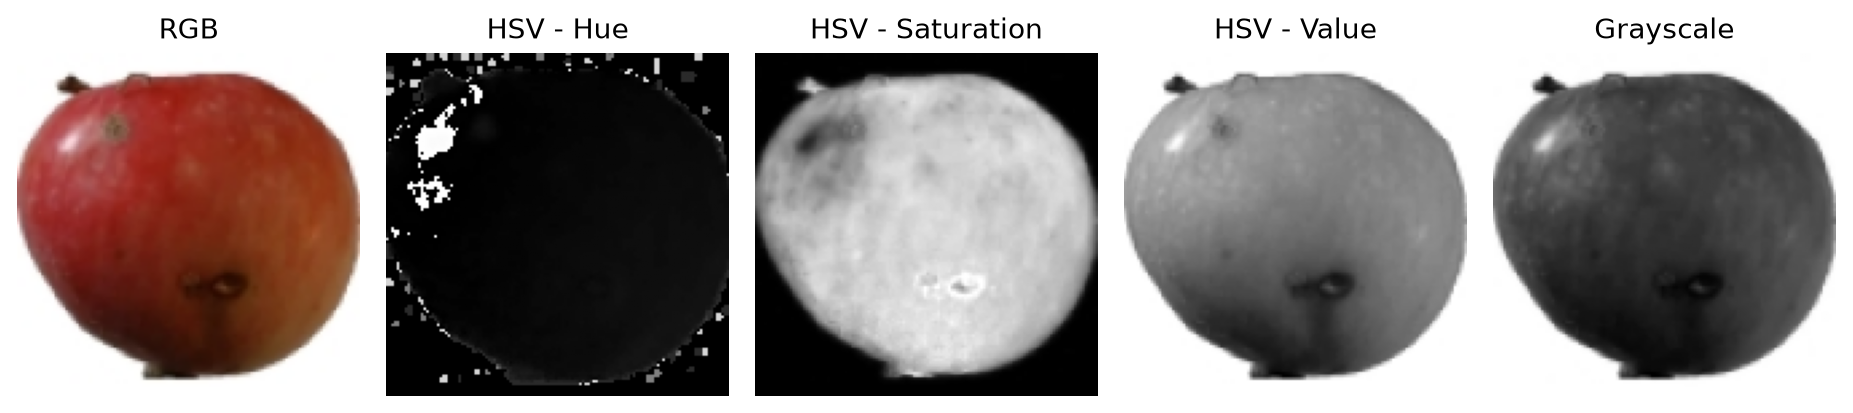

In [2]:
fruit_features, fruit_labels, fruit_rows = extract_fruit_features()
save_feature_csv(fruit_rows, RESULTS_DIR / 'fruit_feature_table.csv')
fruit_preprocessing_path = save_fruit_preprocessing_example()
print('Số ảnh mỗi lớp:', {label: int(sum(fruit_labels == label)) for label in CLASS_NAMES})
print('Vector kết hợp có 37 chiều; bảng CSV có đầy đủ từng bin histogram và nhãn.')
display(Image(filename=str(fruit_preprocessing_path)))

### 1.1. Huấn luyện và đánh giá
Chia Train/Test phân tầng 80/20 (random_state=42). Chuẩn hóa được fit riêng trong pipeline trên tập Train. TN1–TN4 theo đúng cấu hình trong đề.

TN    Đặc trưng      Mô hình  Accuracy Precision    Recall      F1
TN1   rgb_stats      KNN         1.000     1.000     1.000   1.000
TN2   hsv_stats      KNN         1.000     1.000     1.000   1.000
TN3   hsv_hist       SVM         1.000     1.000     1.000   1.000
TN4   all            SVM         1.000     1.000     1.000   1.000
Ảnh test dự đoán đúng: 30 / 30


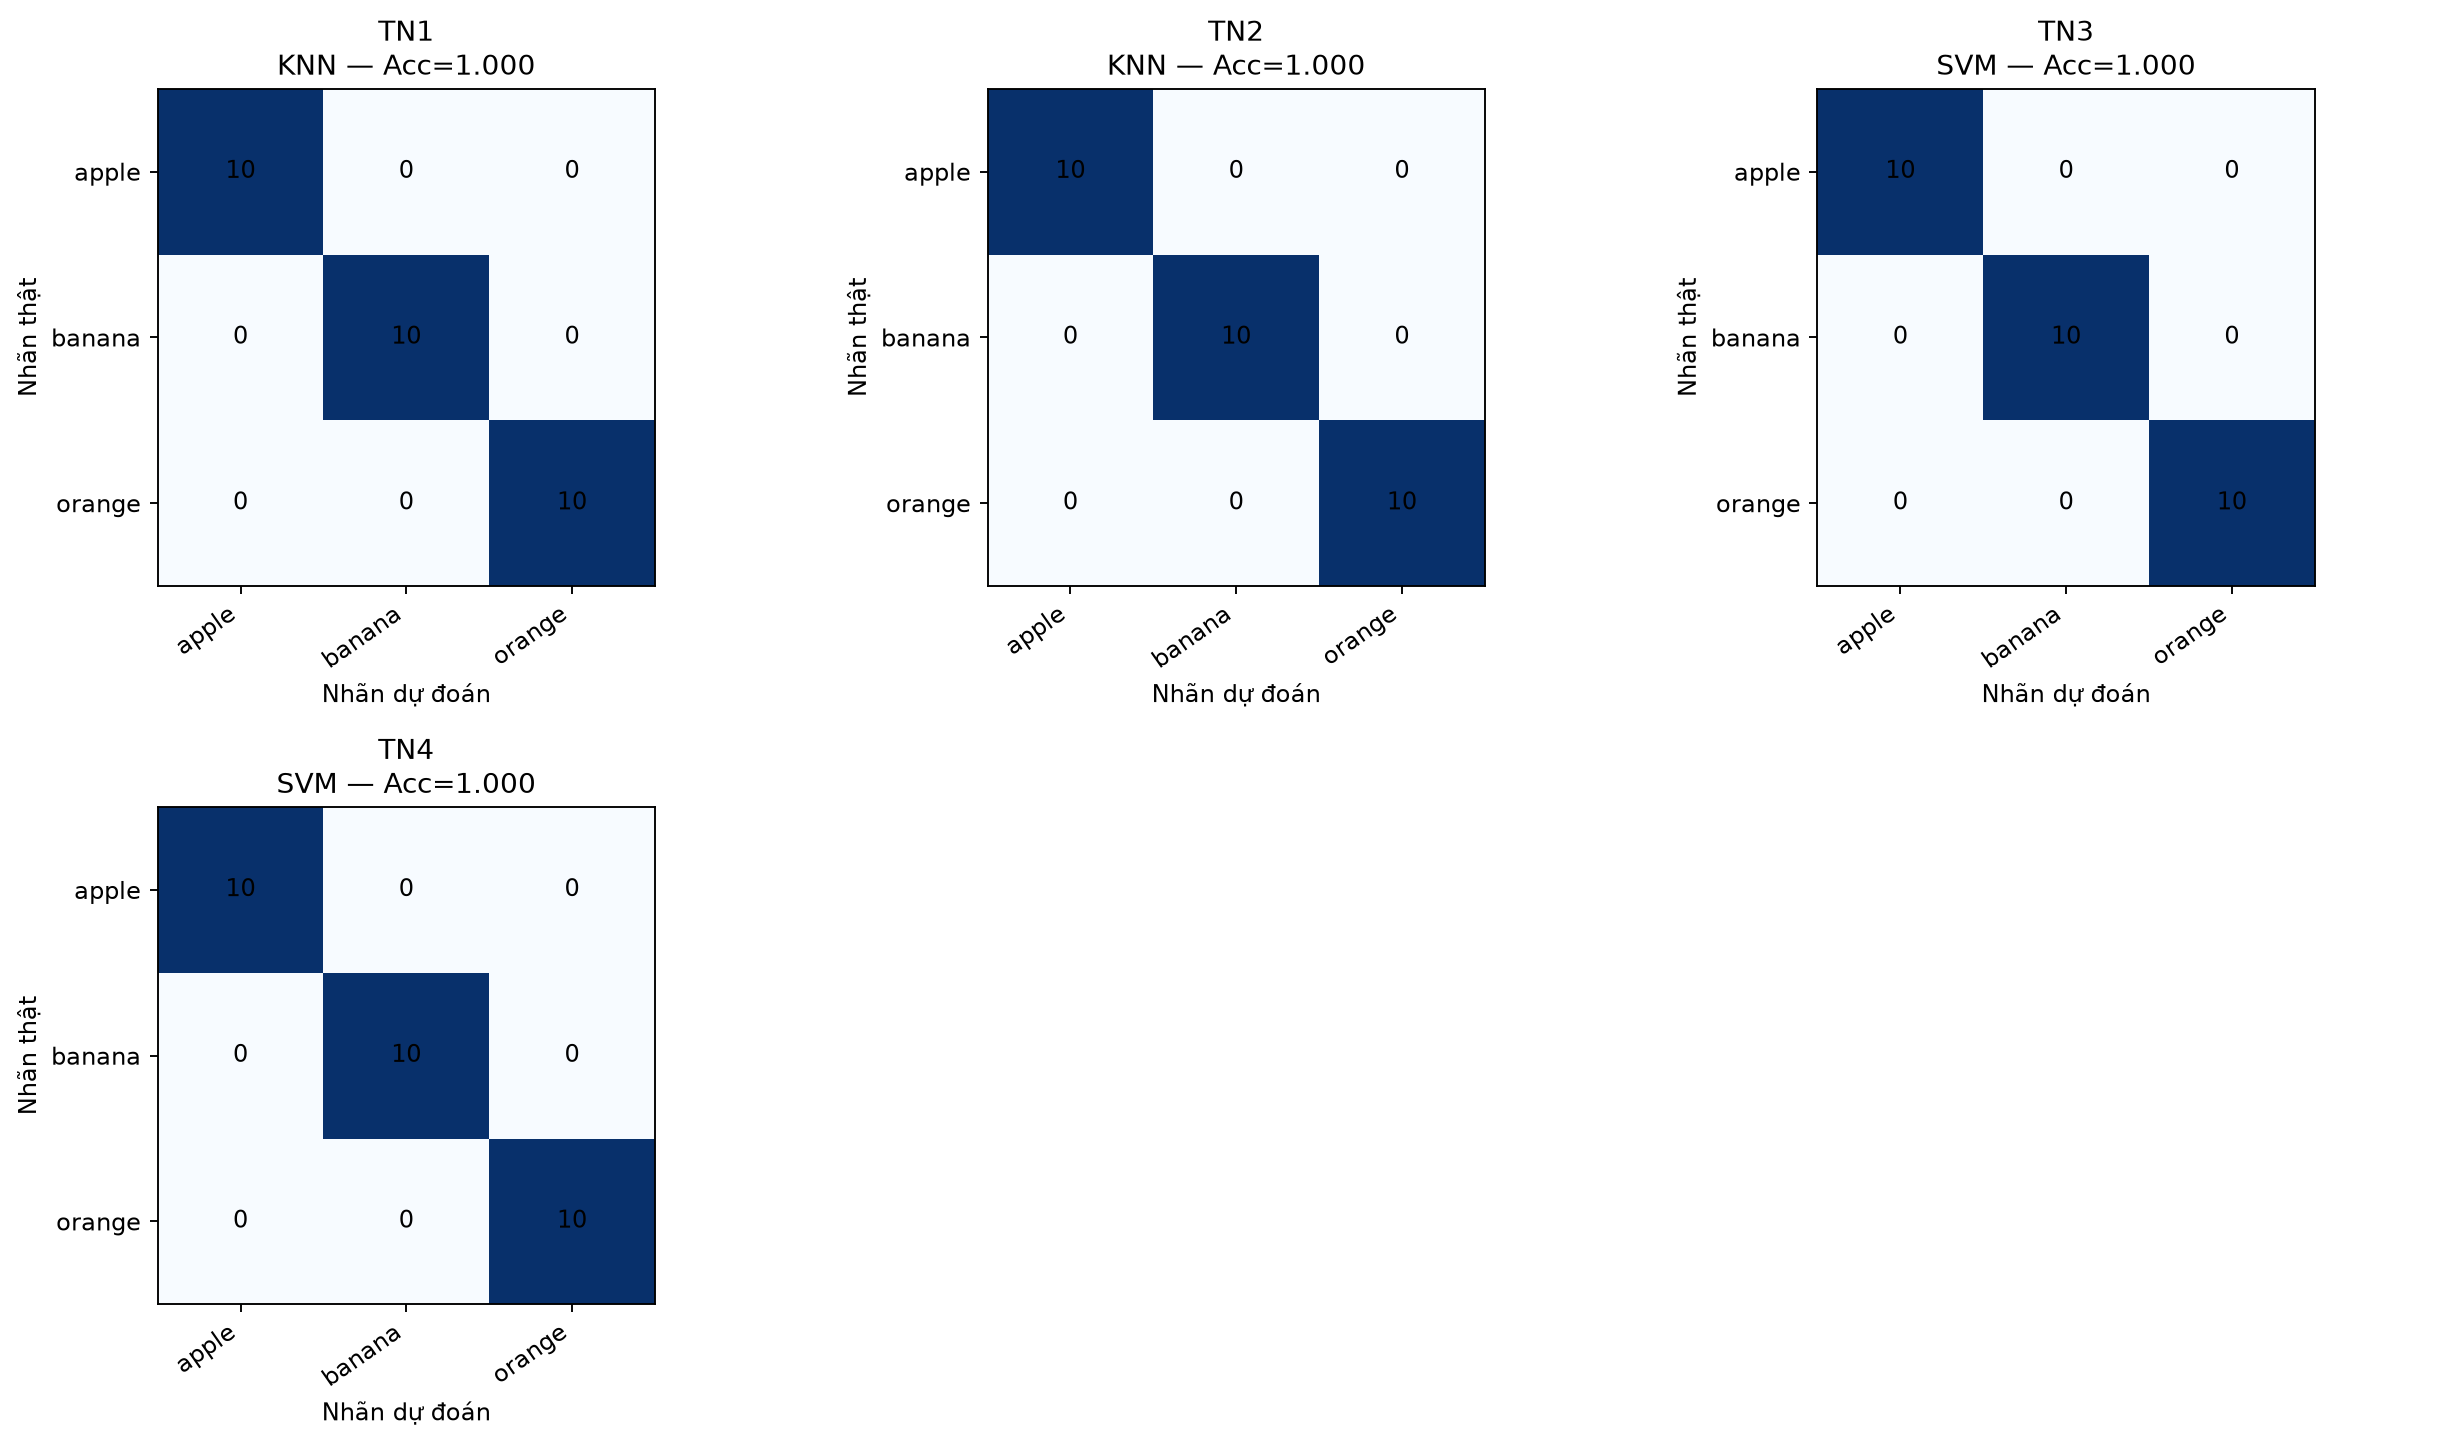

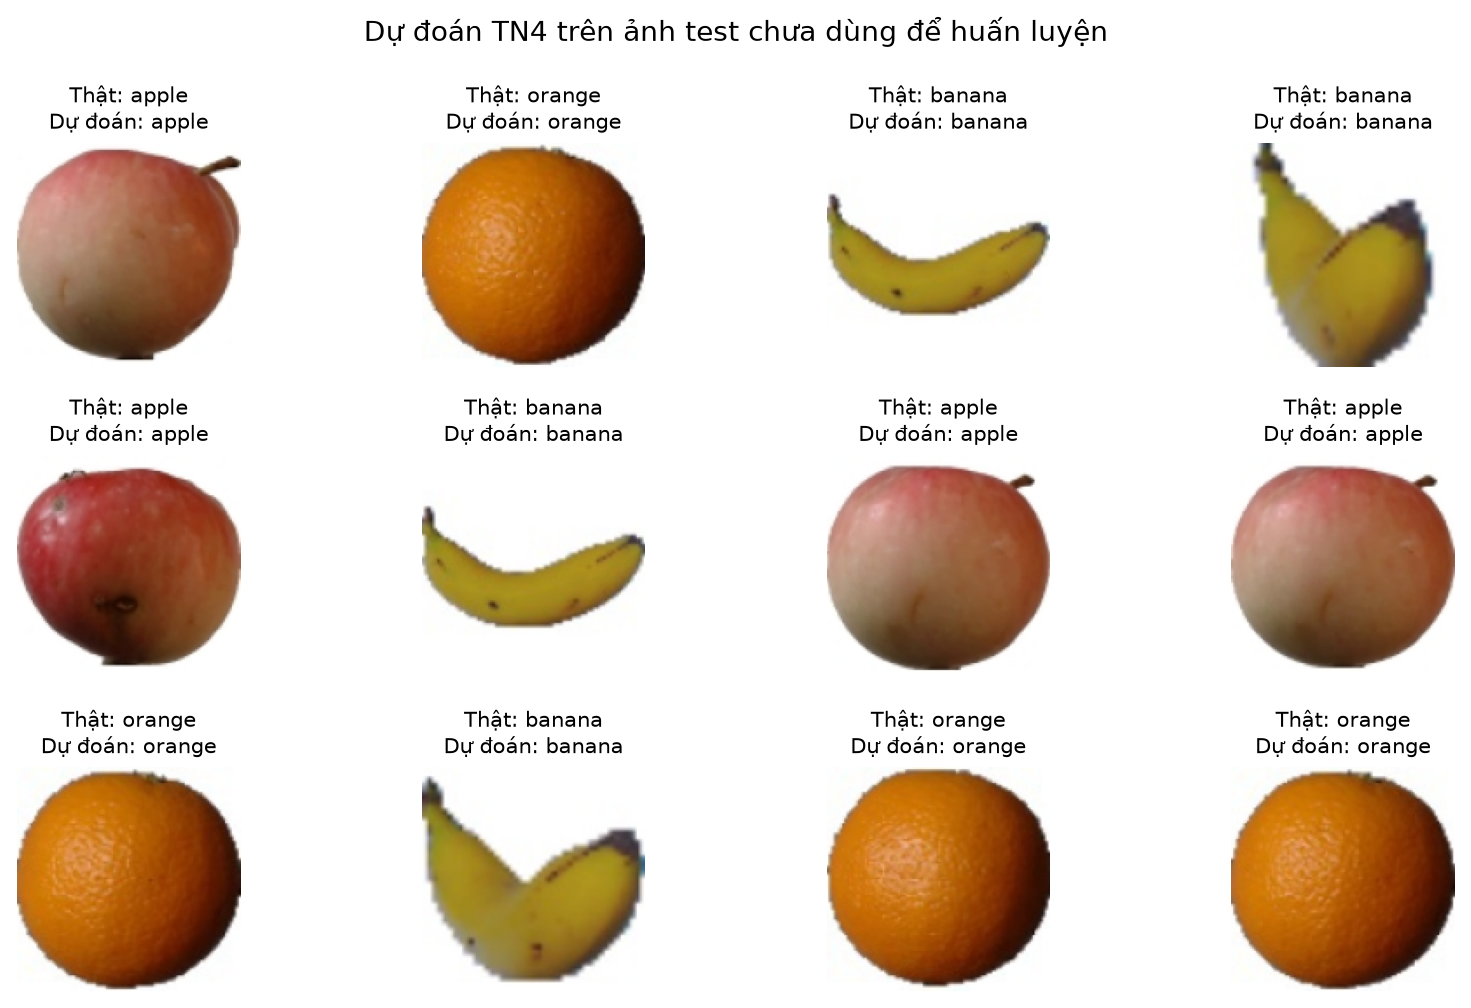

In [3]:
fruit_experiments = [
    ('TN1', 'rgb_stats', 'KNN'),
    ('TN2', 'hsv_stats', 'KNN'),
    ('TN3', 'hsv_hist', 'SVM'),
    ('TN4', 'all', 'SVM'),
]
fruit_records = run_experiments(fruit_features, fruit_labels, fruit_experiments, CLASS_NAMES, 'fruit')
fruit_predictions = save_fruit_prediction_artifacts(fruit_records, fruit_rows)
records_to_json(fruit_records, RESULTS_DIR / 'fruit_results.json')
print(f"{'TN':<5} {'Đặc trưng':<14} {'Mô hình':<7} {'Accuracy':>9} {'Precision':>9} {'Recall':>9} {'F1':>7}")
for r in fruit_records:
    print(f"{r['experiment']:<5} {r['feature']:<14} {r['model']:<7} {r['accuracy']:>9.3f} {r['precision_macro']:>9.3f} {r['recall_macro']:>9.3f} {r['f1_macro']:>7.3f}")
print('Ảnh test dự đoán đúng:', sum(row['correct'] for row in fruit_predictions), '/', len(fruit_predictions))
display(Image(filename=str(RESULTS_DIR / 'fruit_confusion_matrices.png')))
display(Image(filename=str(RESULTS_DIR / 'fruit_test_predictions.png')))

## 2. Bài 2 — Phân loại hình dạng
Sinh 60 ảnh mỗi lớp, thay đổi vị trí, kích thước, góc quay, màu, làm mờ và nhiễu nhẹ. Tiền xử lý gồm Grayscale, Gaussian blur, Otsu, Canny và Contour. Vector hình học có 9 chiều; HOG có 1.764 chiều.

Số ảnh mỗi lớp: {'circle': 60, 'square': 60, 'triangle': 60}
Số chiều hình học: 9
Số chiều HOG: 1764


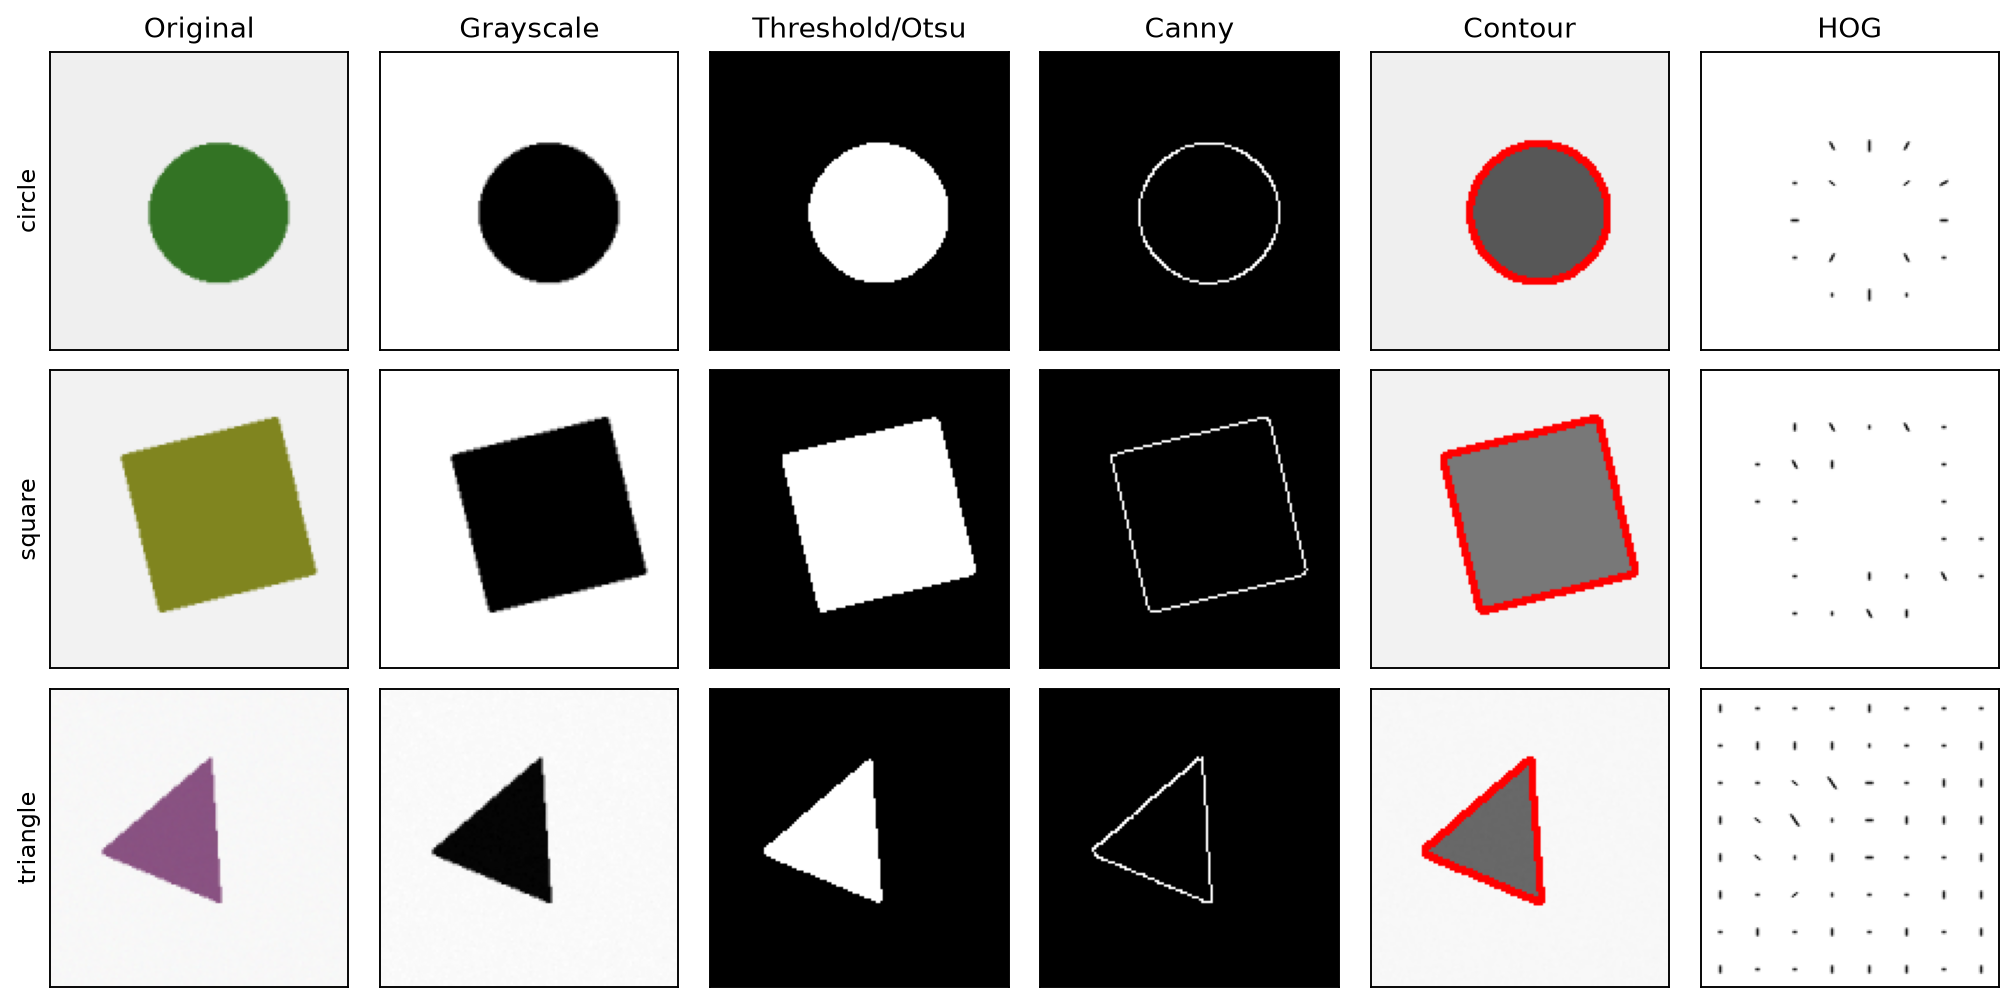

In [4]:
generate_shape_dataset()
shape_features, shape_labels, shape_rows, shape_previews = extract_shape_features()
save_feature_csv(shape_rows, RESULTS_DIR / 'shape_feature_table.csv')
print('Số ảnh mỗi lớp:', {label: int(sum(shape_labels == label)) for label in SHAPE_NAMES})
print('Số chiều hình học:', shape_features['geometry'].shape[1])
print('Số chiều HOG:', shape_features['hog'].shape[1])
display_shape_previews(shape_previews, RESULTS_DIR / 'shape_preprocessing.png')
display(Image(filename=str(RESULTS_DIR / 'shape_preprocessing.png')))

### 2.1. So sánh các mô hình và đặc trưng
Đánh giá KNN, SVM và Random Forest trên đặc trưng hình học, HOG, và kết hợp hình học + HOG.

Thí nghiệm                   Mô hình         Accuracy Precision    Recall      F1
Hình học / KNN               KNN                1.000     1.000     1.000   1.000
Hình học / SVM               SVM                1.000     1.000     1.000   1.000
Hình học / Random Forest     Random Forest      1.000     1.000     1.000   1.000
HOG / KNN                    KNN                0.694     0.774     0.694   0.688
HOG / SVM                    SVM                0.917     0.933     0.917   0.915
HOG / Random Forest          Random Forest      0.944     0.952     0.944   0.944
Hình học + HOG / KNN         KNN                0.694     0.774     0.694   0.688
Hình học + HOG / SVM         SVM                0.944     0.952     0.944   0.944
Hình học + HOG / Random Forest Random Forest      0.917     0.933     0.917   0.915
Ảnh độc lập được phân loại đúng: 3 / 3


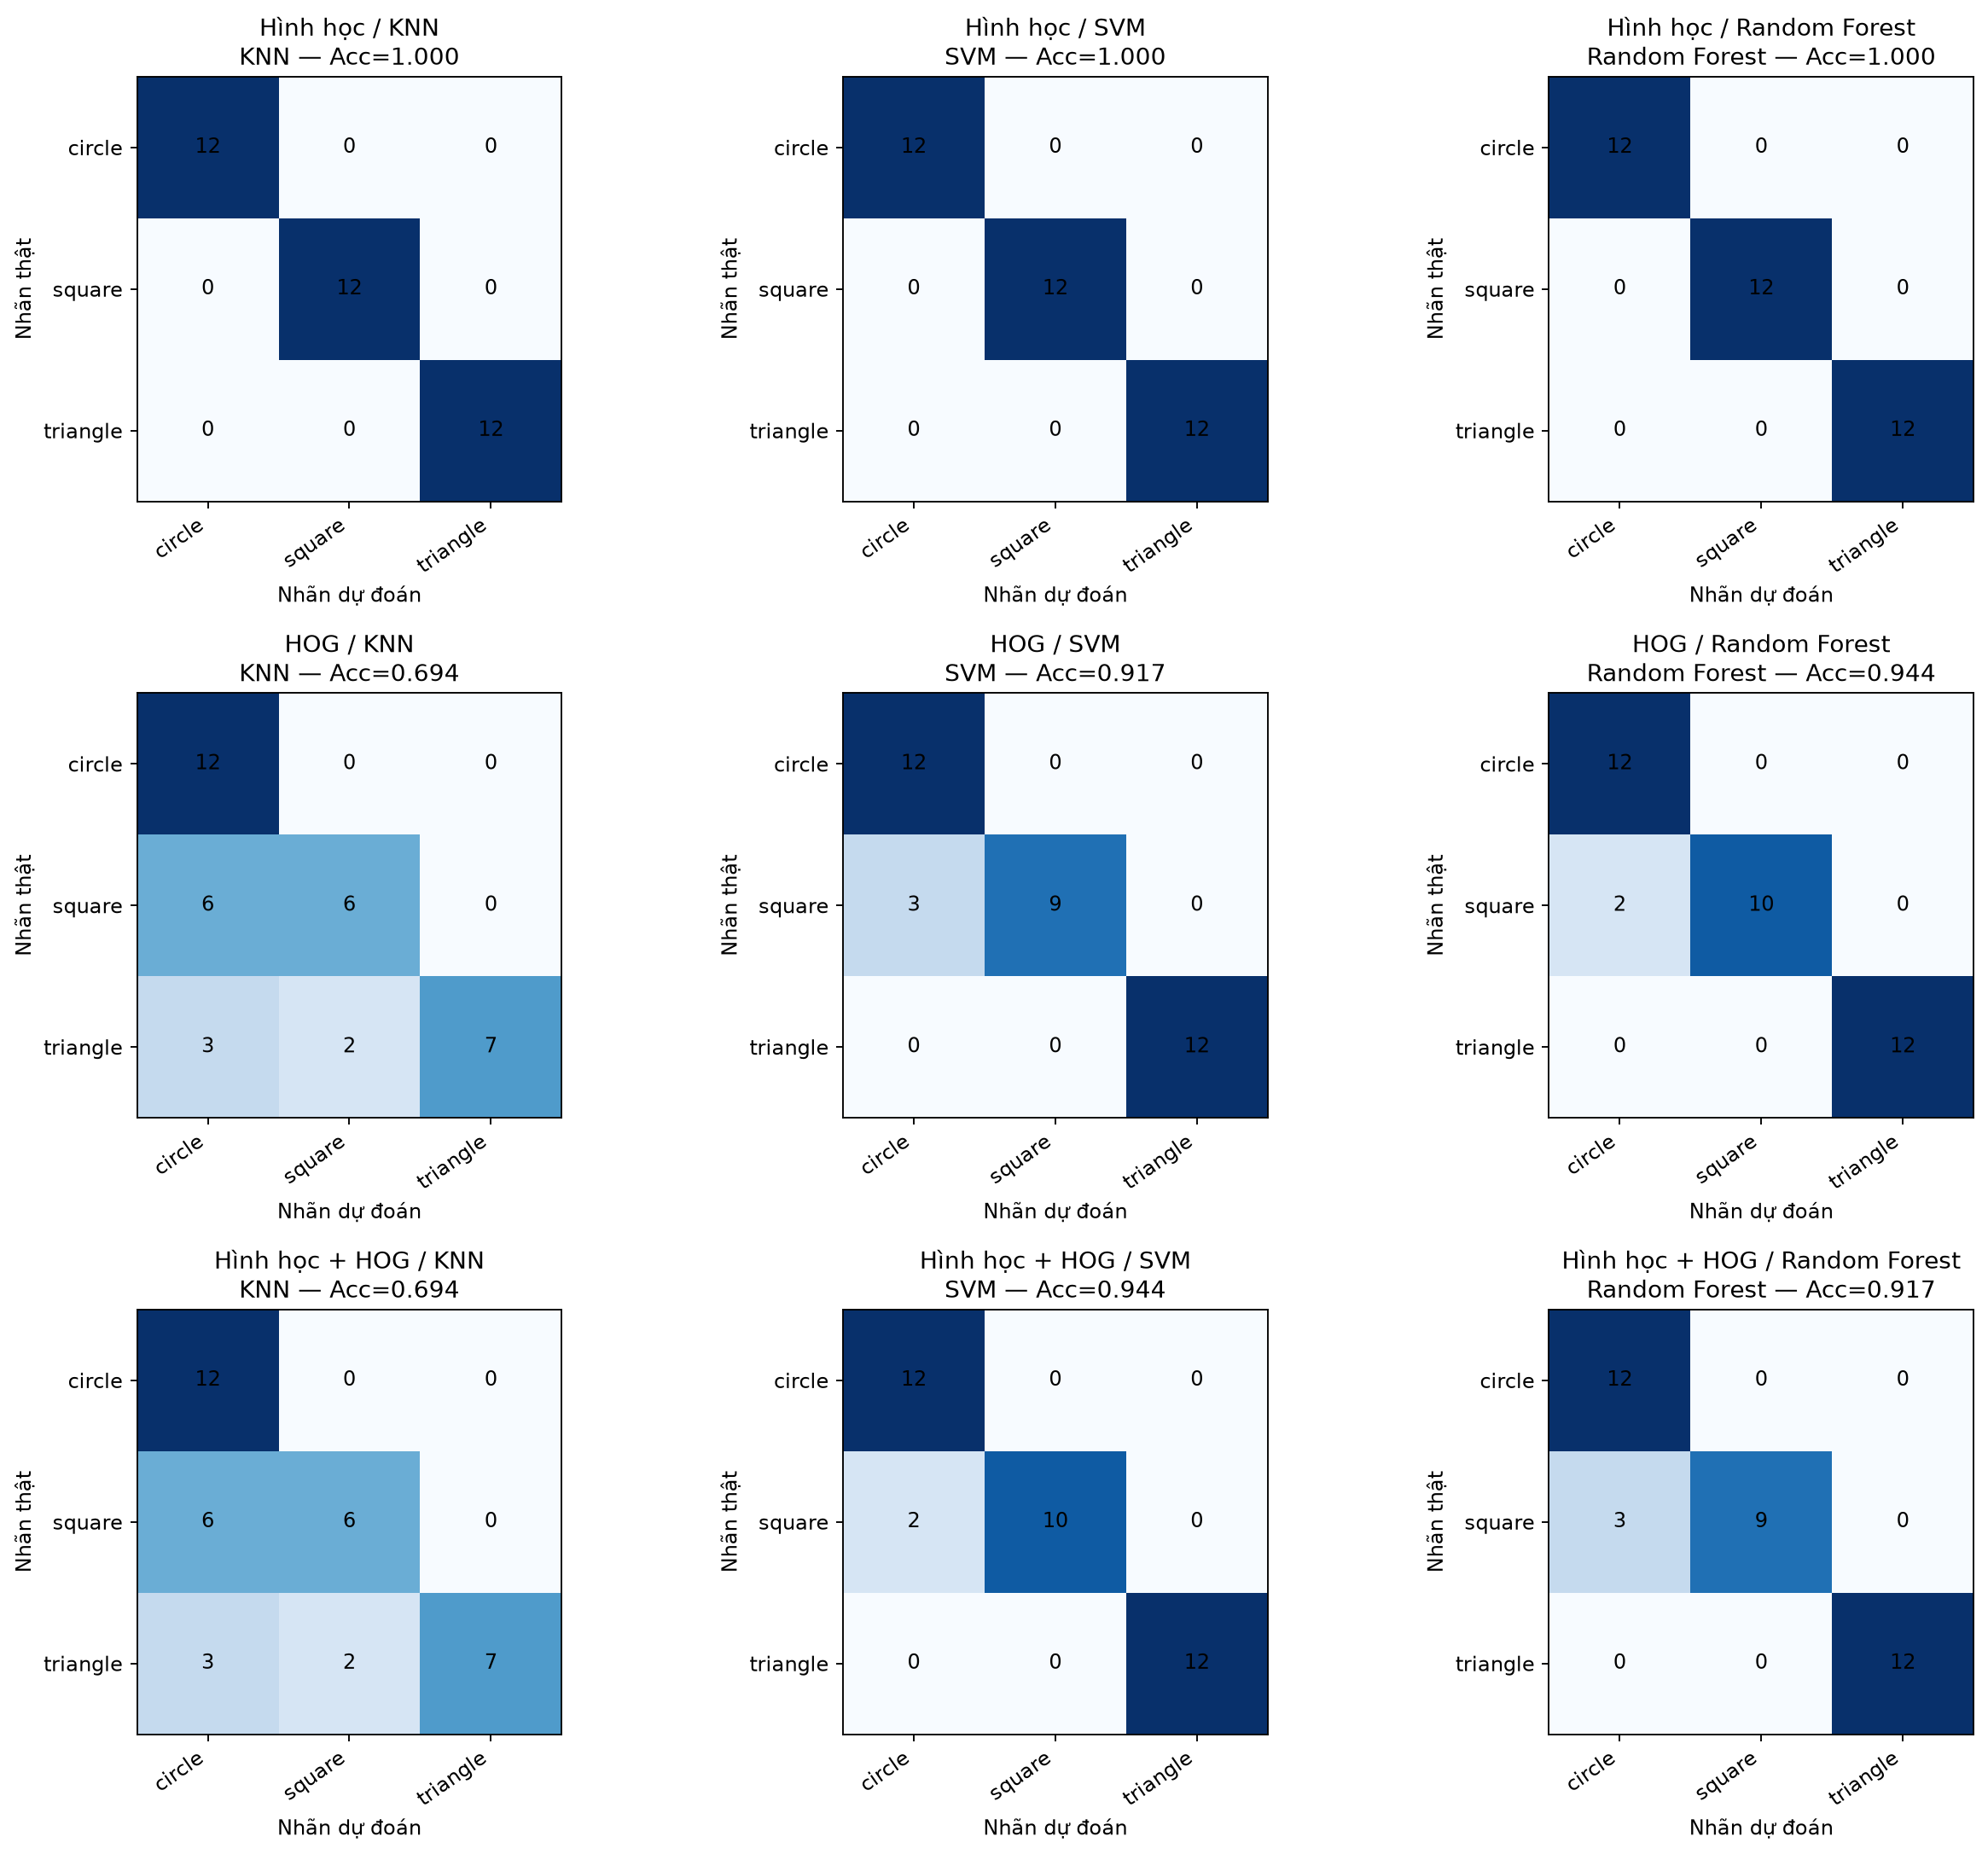

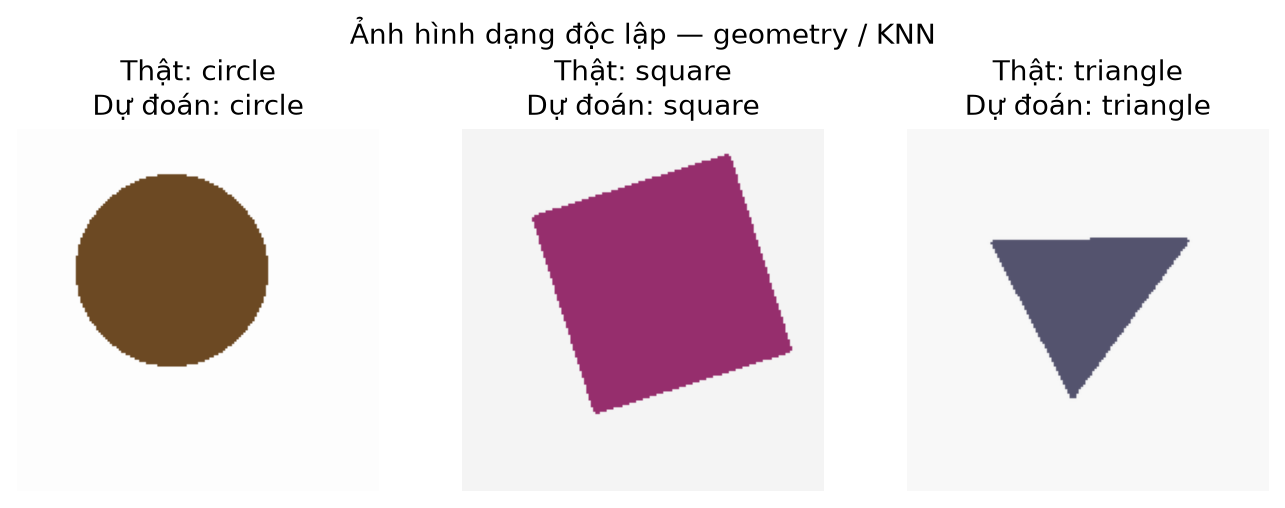

In [5]:
import numpy as np
shape_features['combined'] = np.concatenate([shape_features['geometry'], shape_features['hog']], axis=1)
shape_experiments = [
    (f'{feature_name} / {model_name}', feature_key, model_name)
    for feature_name, feature_key in [('Hình học', 'geometry'), ('HOG', 'hog'), ('Hình học + HOG', 'combined')]
    for model_name in ('KNN', 'SVM', 'Random Forest')
]
shape_records = run_experiments(shape_features, shape_labels, shape_experiments, SHAPE_NAMES, 'shape')
records_to_json(shape_records, RESULTS_DIR / 'shape_results.json')
shape_predictions, selected_shape_model = predict_unseen_shape_samples(shape_features, shape_labels, shape_records)
print(f"{'Thí nghiệm':<28} {'Mô hình':<14} {'Accuracy':>9} {'Precision':>9} {'Recall':>9} {'F1':>7}")
for r in shape_records:
    print(f"{r['experiment']:<28} {r['model']:<14} {r['accuracy']:>9.3f} {r['precision_macro']:>9.3f} {r['recall_macro']:>9.3f} {r['f1_macro']:>7.3f}")
print('Ảnh độc lập được phân loại đúng:', sum(row['correct'] for row in shape_predictions), '/', len(shape_predictions))
display(Image(filename=str(RESULTS_DIR / 'shape_confusion_matrices.png')))
display(Image(filename=str(RESULTS_DIR / 'shape_unseen_predictions.png')))

## 3. Tạo báo cáo Word
Báo cáo gồm mô tả phương pháp, cấu hình mô hình, bảng số liệu, ma trận nhầm lẫn, dự đoán ảnh mới, phân tích lỗi và câu trả lời thảo luận. Điền thông tin cá nhân trong trang đầu trước khi nộp.

In [6]:
report_path = create_report(
    fruit_records, shape_records, fruit_predictions, shape_predictions, fruit_rows, shape_rows
)
print('Đã tạo báo cáo chỉnh sửa được:', report_path)
print('Tất cả tệp bảng, ảnh và metrics nằm trong:', RESULTS_DIR)

Đã tạo báo cáo chỉnh sửa được: D:\XuLyAnh\thuc_hanh_tuan_6\bao_cao_tuan_6.docx
Tất cả tệp bảng, ảnh và metrics nằm trong: D:\XuLyAnh\thuc_hanh_tuan_6\results


## 4. Tệp đầu ra
- `bao_cao_tuan_6.docx`: báo cáo Word.
- `week6_solution.py`: mã nguồn chạy toàn bộ pipeline.
- `results/*_feature_table.csv`: vector đặc trưng đầy đủ kèm nhãn.
- `results/*_metrics.csv` và `*_results.json`: chỉ số đánh giá.
- `results/*_predictions.csv`: dự đoán trên ảnh test và ảnh hình dạng độc lập.
- `dataset_shapes/`, `dataset_shapes_unseen/`: dữ liệu hình dạng và ảnh mới dùng suy luận.